# Univerity Ranking 

**Scenario**

An education consulting company wants to build insights for students applying abroad.

**Tasks**
1. Analyze ranking distribution by country.
2. Identify:
- Top universities by region
- Countries dominating global education
- Score trends
3. Compare rankings and academic reputation scores.
4. Find countries with the highest average university scores.
5. Build ranking-based insights for students.


**Required Visualizations**

Minimum 3:
- Bar Chart → Top countries by university count
- Scatter Plot → Rank vs Score
- Pie Chart → Regional distribution
Optional:
- Violin Plot
- Histogram
- Heatmap


**Concepts Covered**

1. Ranking analysis
2. Aggregation
3. Sorting
4. Descriptive statistics
5. Comparative analytics

**Scrape the data from QS univerity ranking using Crwal4ai**


## This is main file

##Tis is small file

## Installation and Imports

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
!pip install faker numpy pandas matplotlib pytorch

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  error: subprocess-exited-with-error
  
  × Building wheel for pytorch (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> [37 lines of output]
      Traceback (most recent call last):
        File "/Users/adityapathania/Codes/bz/BL-Practice_Python/.venv-bl/lib/python3.14/site-packages/pip/_vendor/pyproject_hooks/_in_process/_in_process.py", line 389, in <module>
          main()
          ~~~~^^
        File "/Users/adityapathania/Codes/bz/BL-Practice_Python/.venv-bl/lib/python3.14/site-packages/pip/_vendor/pyproject_hooks/_in_process/_in_process.py", line 373, in main
          json_out["return_val"] = hook(**hook_input["kwargs"])
                                   ~~~~^^^^^^^^^^^^^^^^^^^^^^^^
        File "/Users/adityapathania/Codes/bz/BL-Practice_Python/.venv-bl/lib/python3.14/site-packages/pip/_vendor/pyproject_hooks/_in_process/_in

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


## Test the GPU

In [ ]:
print(torch.cuda.is_available())
device = torch.device("cuda")
print(torch.cuda.get_device_name(0))
print('Memory Usage:')
print('Allocated:', round(torch.cuda.memory_allocated(0)/1024**3,1), 'GB')
print('Cached:', round(torch.cuda.memory_reserved(0)/1024**3,1), 'GB')

## Data Reading

In [ ]:
data = pd.read_csv('./data/university_data.csv' , encoding='latin1')

In [ ]:
data.head()

,RANK_2025,RANK_2024,Institution_Name,Location,Region,SIZE,FOCUS,RES.,STATUS,Academic_Reputation_Score,...,International_Faculty_Rank,International_Students_Score,International_Students_Rank,International_Research_Network_Score,International_Research_Network_Rank,Employment_Outcomes_Score,Employment_Outcomes_Rank,Sustainability_Score,Sustainability_Rank,Overall_Score
0,1,1,Massachusetts Institute of Technology (MIT),United States,Americas,M,CO,VH,B,100.0,...,100,86.8,143,96.0,58,100.0,8,99.0,15=,100
1,2,6,Imperial College London,United Kingdom,Europe,L,FC,VH,A,98.5,...,66,99.6,44,97.4,34,93.4,61,99.7,6,98.5
2,3,3,University of Oxford,United Kingdom,Europe,L,FC,VH,A,100.0,...,120,97.7,73,100.0,1,100.0,3,85.0,126,96.9
3,4,4,Harvard University,United States,Americas,L,FC,VH,B,100.0,...,269,69.0,215,99.6,5,100.0,1,84.4,130,96.8
4,5,2,University of Cambridge,United Kingdom,Europe,L,FC,VH,A,100.0,...,73,94.8,98,99.3,10,100.0,5,84.8,127=,96.7


In [ ]:
print("Data Shape is : " , data.shape)
print("Data Size is : " , data.size)

Data Shape is :  (1503, 28)
Data Size is :  42084


In [ ]:
print(data.columns)

Index(['RANK_2025', 'RANK_2024', 'Institution_Name', 'Location', 'Region',
       'SIZE', 'FOCUS', 'RES.', 'STATUS', 'Academic_Reputation_Score',
       'Academic_Reputation_Rank', 'Employer_Reputation_Score',
       'Employer_Reputation_Rank', 'Faculty_Student_Score',
       'Faculty_Student_Rank', 'Citations_per_Faculty_Score',
       'Citations_per_Faculty_Rank', 'International_Faculty_Score',
       'International_Faculty_Rank', 'International_Students_Score',
       'International_Students_Rank', 'International_Research_Network_Score',
       'International_Research_Network_Rank', 'Employment_Outcomes_Score',
       'Employment_Outcomes_Rank', 'Sustainability_Score',
       'Sustainability_Rank', 'Overall_Score'],
      dtype='str')


## Data Clusterung Region vise and visualization

In [ ]:
score_cols = [
      col for col in data.columns
      if col.endswith("_Score")
  ]
score_cols

['Academic_Reputation_Score',
 'Employer_Reputation_Score',
 'Faculty_Student_Score',
 'Citations_per_Faculty_Score',
 'International_Faculty_Score',
 'International_Students_Score',
 'International_Research_Network_Score',
 'Employment_Outcomes_Score',
 'Sustainability_Score',
 'Overall_Score']

In [ ]:
for col in score_cols:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data[score_cols].head()

,Academic_Reputation_Score,Employer_Reputation_Score,Faculty_Student_Score,Citations_per_Faculty_Score,International_Faculty_Score,International_Students_Score,International_Research_Network_Score,Employment_Outcomes_Score,Sustainability_Score,Overall_Score
0,100.0,100.0,100.0,100.0,99.3,86.8,96.0,100.0,99.0,100.0
1,98.5,99.5,98.2,93.9,100.0,99.6,97.4,93.4,99.7,98.5
2,100.0,100.0,100.0,84.8,98.1,97.7,100.0,100.0,85.0,96.9
3,100.0,100.0,96.3,100.0,74.1,69.0,99.6,100.0,84.4,96.8
4,100.0,100.0,100.0,84.6,100.0,94.8,99.3,100.0,84.8,96.7


In [ ]:
for col in score_cols:
    data[col] = pd.to_numeric(data[col], errors="coerce")

x = data[score_cols].copy()

x

,Academic_Reputation_Score,Employer_Reputation_Score,Faculty_Student_Score,Citations_per_Faculty_Score,International_Faculty_Score,International_Students_Score,International_Research_Network_Score,Employment_Outcomes_Score,Sustainability_Score,Overall_Score
0,100.0,100.0,100.0,100.0,99.3,86.8,96.0,100.0,99.0,100.0
1,98.5,99.5,98.2,93.9,100.0,99.6,97.4,93.4,99.7,98.5
2,100.0,100.0,100.0,84.8,98.1,97.7,100.0,100.0,85.0,96.9
3,100.0,100.0,96.3,100.0,74.1,69.0,99.6,100.0,84.4,96.8
4,100.0,100.0,100.0,84.6,100.0,94.8,99.3,100.0,84.8,96.7
...,...,...,...,...,...,...,...,...,...,...
1498,3.0,2.2,10.6,6.1,1.3,1.9,6.5,3.1,1.0,NaN
1499,5.6,2.2,4.0,1.9,1.5,5.2,34.5,6.2,2.3,NaN
1500,7.2,9.4,3.3,1.8,2.1,2.1,6.4,9.6,1.0,NaN
1501,4.1,4.2,7.2,3.9,1.4,2.5,18.6,3.9,1.1,NaN


Number of countries: 106
Location
United States             197
United Kingdom             90
China (Mainland)           71
Japan                      49
Germany                    48
                         ... 
Sudan                       1
Bosnia and Herzegovina      1
Syrian Arab Republic        1
Guatemala                   1
Honduras                    1
Name: count, Length: 106, dtype: int64


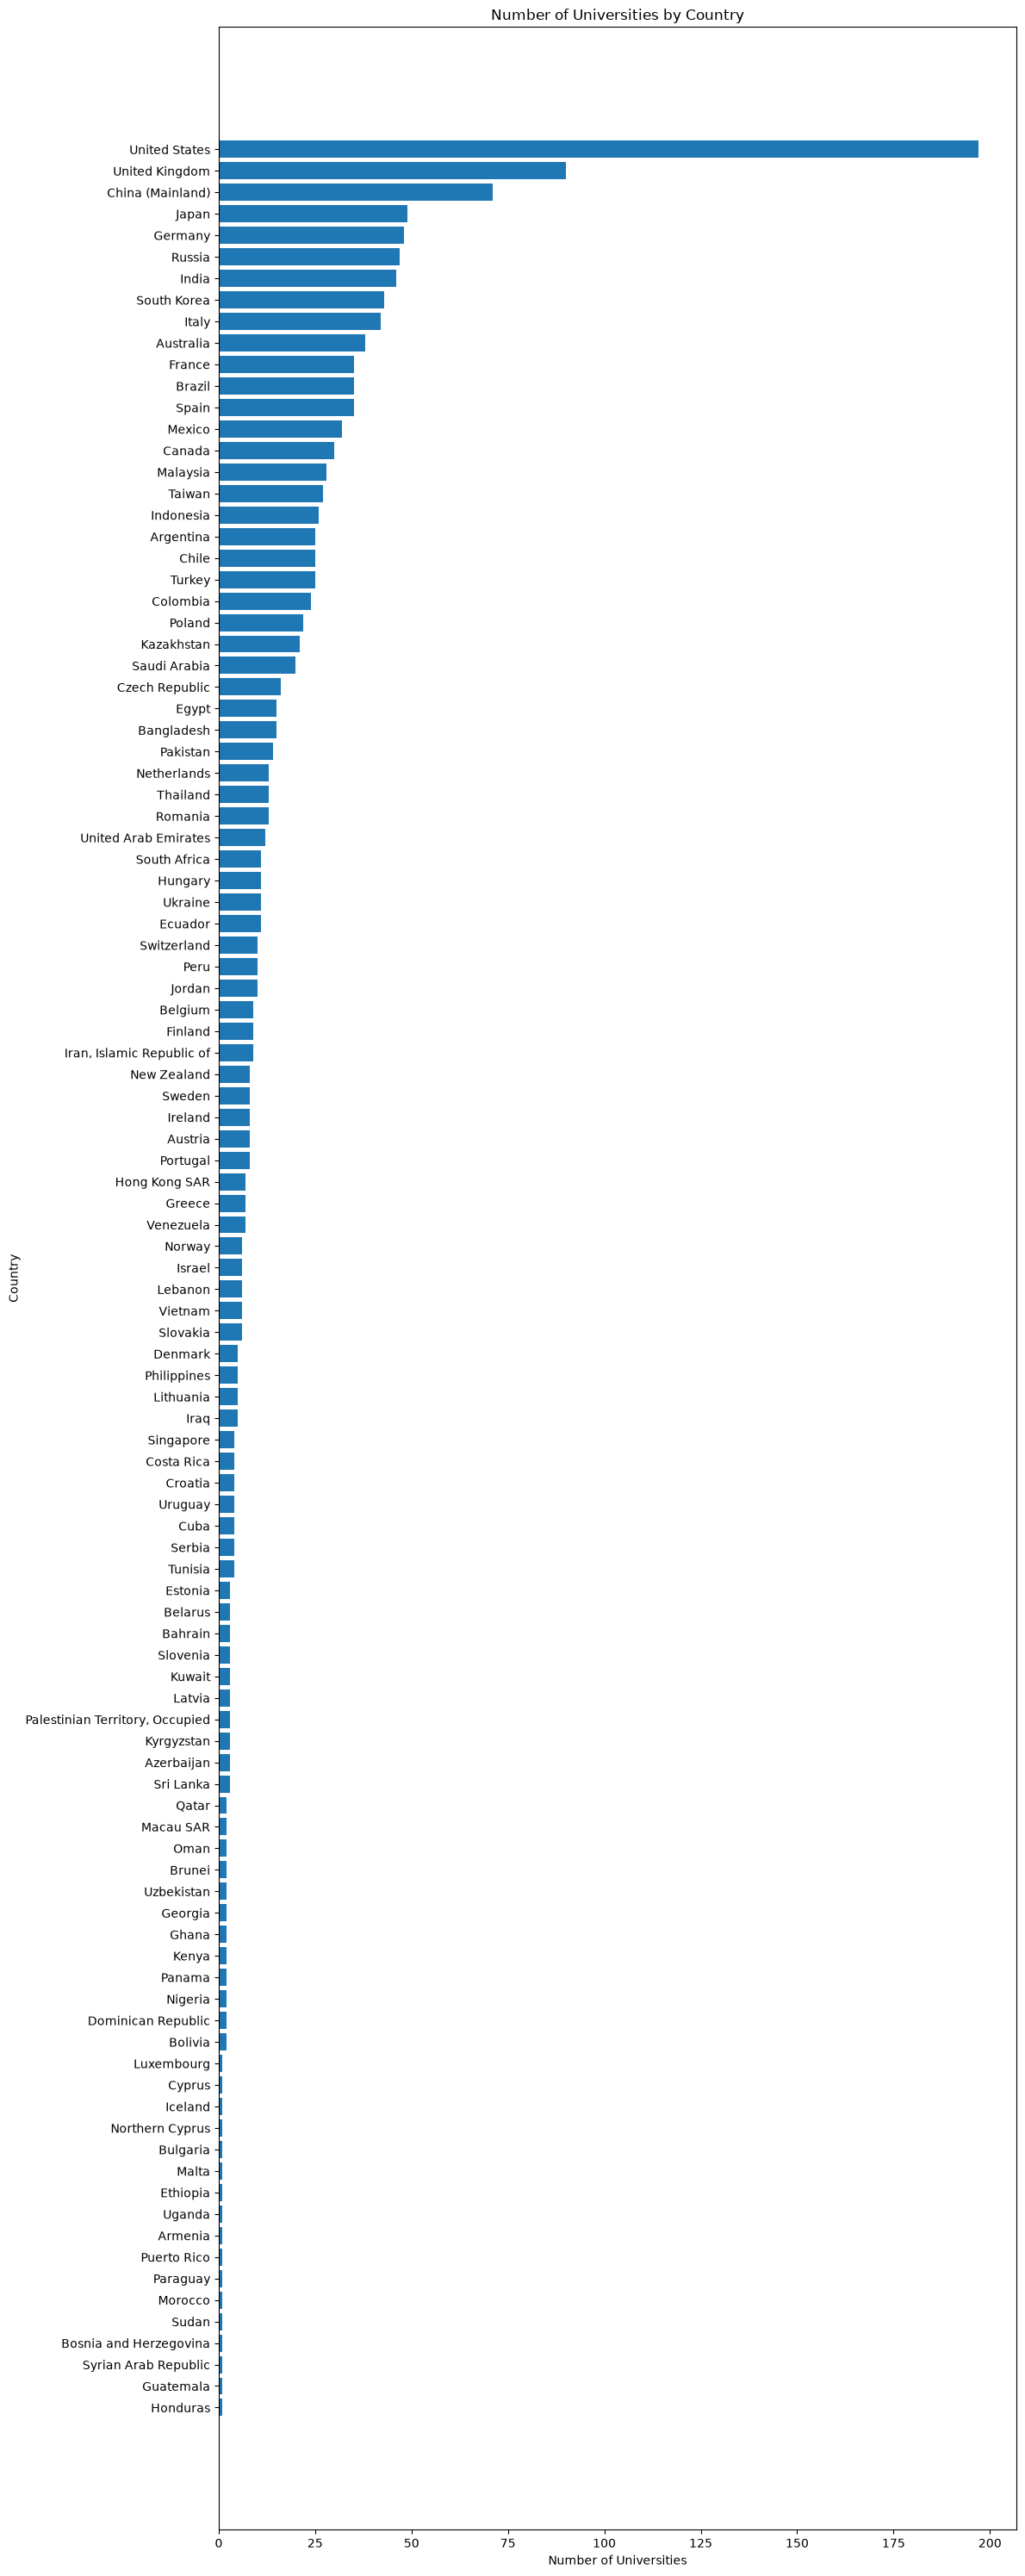

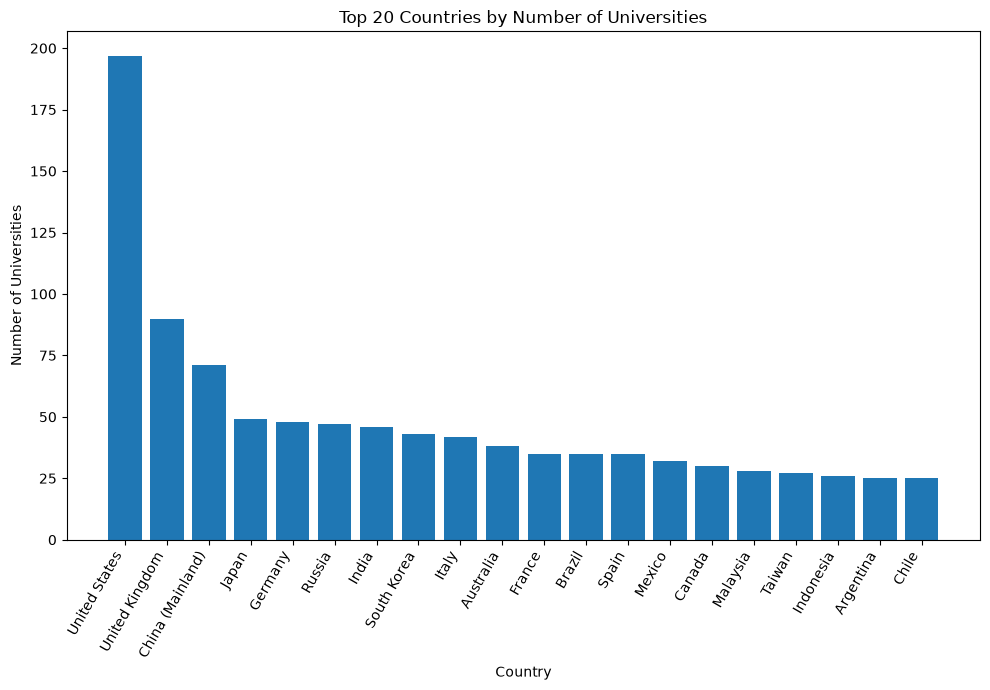

In [ ]:
country_counts = data["Location"].value_counts()

print("Number of countries:", country_counts.size)

  # Display the counts
print(country_counts)

plt.figure(figsize=(12, 30))

plt.barh(
    country_counts.index,
    country_counts.values
)

plt.xlabel("Number of Universities")
plt.ylabel("Country")
plt.title("Number of Universities by Country")

  # Put the country with the most universities at the top
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

top_20 = country_counts.head(20)

plt.figure(figsize=(10, 7))
plt.bar(top_20.index, top_20.values)

plt.xlabel("Country")
plt.ylabel("Number of Universities")
plt.title("Top 20 Countries by Number of Universities")

plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

                       Location                                                                                                      Institution_Name RANK_2025  Rank_2025_num
                  United States                                                                          Massachusetts Institute of Technology (MIT)          1            1.0
                 United Kingdom                                                                                               Imperial College London         2            2.0
                    Switzerland                                                                    ETH Zurich - Swiss Federal Institute of Technology         7            7.0
                      Singapore                                                                                National University of Singapore (NUS)         8            8.0
                      Australia                                                                                           The

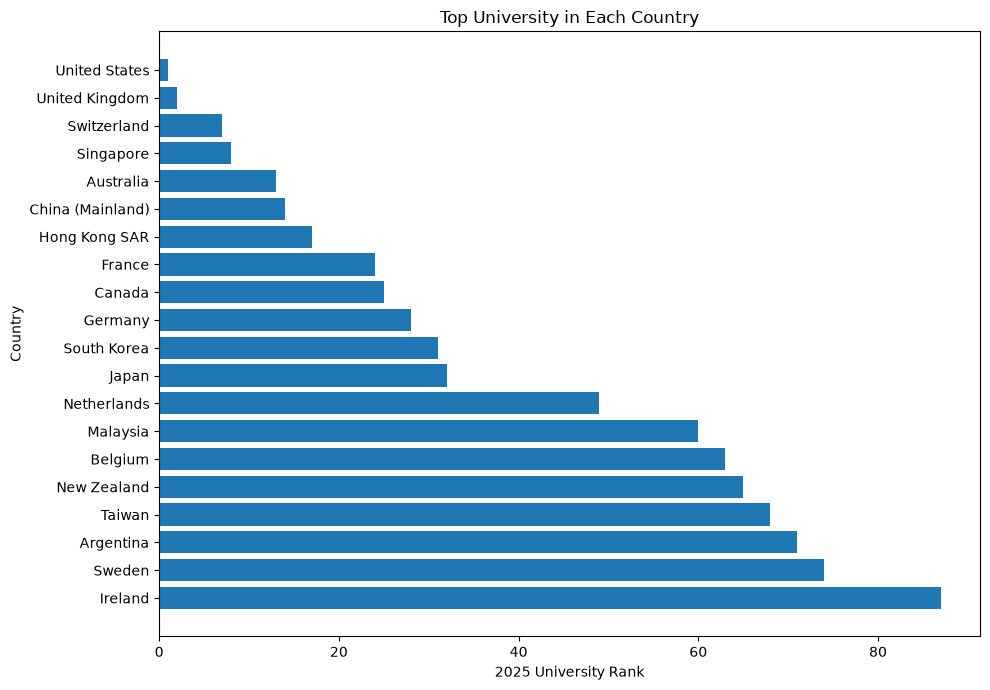

In [ ]:
data["Rank_2025_num"] = (
      data["RANK_2025"]
      .astype(str)
      .str.extract(r"(\d+)")[0]
      .astype(float)
  )

top_universities = (
    data.dropna(subset=["Rank_2025_num"])
          .sort_values(["Location", "Rank_2025_num"])
          .groupby("Location")
          .head(1)
          [["Location", "Institution_Name", "RANK_2025", "Rank_2025_num"]]
          .sort_values("Rank_2025_num")
  )

print(top_universities.to_string(index=False))

  ### Bar graph of the top 20 countries

top_20 = top_universities.head(20)

plt.figure(figsize=(10, 7))

plt.barh(
      top_20["Location"],
      top_20["Rank_2025_num"]
  )

plt.xlabel("2025 University Rank")
plt.ylabel("Country")
plt.title("Top University in Each Country")

  # Lower rank is better
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

STATUS
A          1165
B           249
C            52
Unknown      37
Name: count, dtype: int64


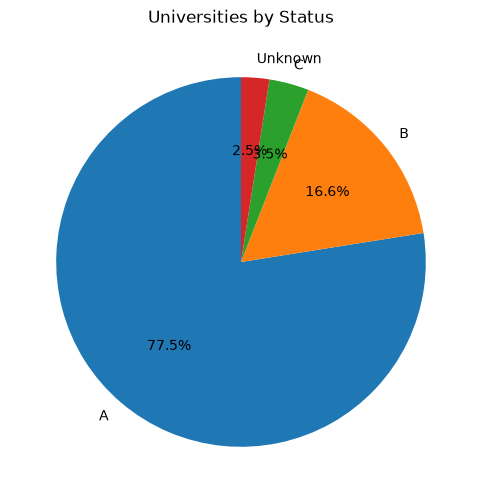

FOCUS
FC    592
CO    480
FO    353
SP     78
Name: count, dtype: int64


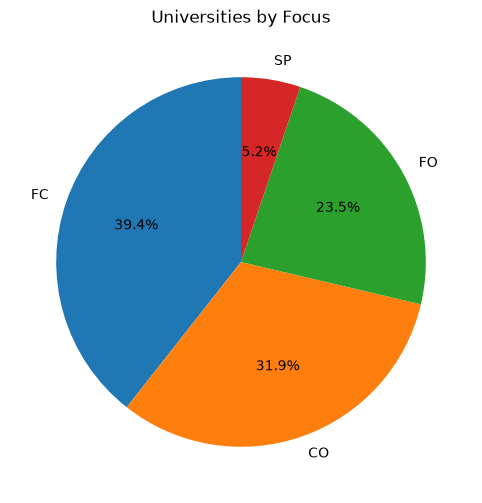

SIZE
L     691
M     372
XL    352
S      88
Name: count, dtype: int64


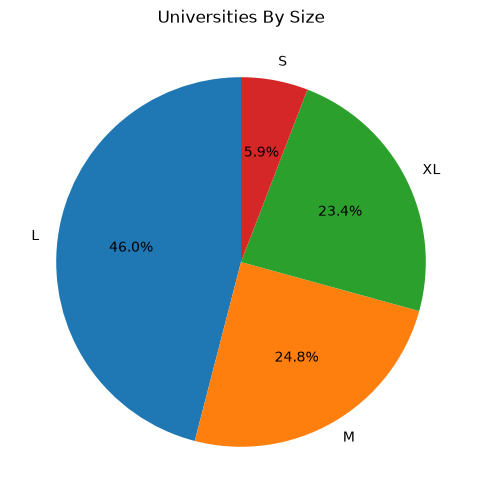

In [ ]:
status_counts = (
      data["STATUS"]
      .fillna("Unknown")
      .value_counts()
  )

print(status_counts)

plt.figure(figsize = (6,6))

plt.pie(status_counts.values, labels=status_counts.index, autopct="%1.1f%%", startangle=90
  )

plt.title("Universities by Status")
plt.show()

focus_counts = (data["FOCUS"].fillna("Unknown").value_counts()
  )

print(focus_counts)

plt.figure(figsize = (6,6))

plt.pie(focus_counts.values, labels=focus_counts.index, autopct="%1.1f%%", startangle=90 )

plt.title("Universities by Focus")
plt.show()

size_count = data["SIZE"].fillna("Unknown").value_counts()

print(size_count)

plt.figure(figsize = (6,6))

plt.pie( size_count , labels = size_count.index , autopct= "%1.1f%%" , startangle = 90)

plt.title("Universities By Size")
plt.show()

FOCUS
FC    592
CO    480
FO    353
SP     78
Name: count, dtype: int64


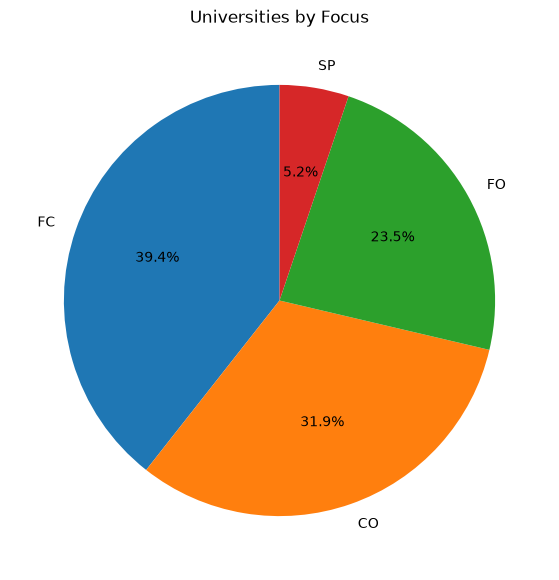

In [ ]:
focus_counts = (
      data["FOCUS"]
      .fillna("Unknown")
      .value_counts()
  )

print(focus_counts)

plt.figure(figsize=(7, 7))

plt.pie(
    focus_counts.values,
    labels=focus_counts.index,
    autopct="%1.1f%%",
    startangle=90
  )

plt.title("Universities by Focus")
plt.show()

In [ ]:
  # Fill missing values
x = x.fillna(x.median())
x

,Academic_Reputation_Score,Employer_Reputation_Score,Faculty_Student_Score,Citations_per_Faculty_Score,International_Faculty_Score,International_Students_Score,International_Research_Network_Score,Employment_Outcomes_Score,Sustainability_Score,Overall_Score
0,100.0,100.0,100.0,100.0,99.3,86.8,96.0,100.0,99.0,100.00
1,98.5,99.5,98.2,93.9,100.0,99.6,97.4,93.4,99.7,98.50
2,100.0,100.0,100.0,84.8,98.1,97.7,100.0,100.0,85.0,96.90
3,100.0,100.0,96.3,100.0,74.1,69.0,99.6,100.0,84.4,96.80
4,100.0,100.0,100.0,84.6,100.0,94.8,99.3,100.0,84.8,96.70
...,...,...,...,...,...,...,...,...,...,...
1498,3.0,2.2,10.6,6.1,1.3,1.9,6.5,3.1,1.0,36.35
1499,5.6,2.2,4.0,1.9,1.5,5.2,34.5,6.2,2.3,36.35
1500,7.2,9.4,3.3,1.8,2.1,2.1,6.4,9.6,1.0,36.35
1501,4.1,4.2,7.2,3.9,1.4,2.5,18.6,3.9,1.1,36.35


In [ ]:
k = 3
max_iterations = 100
tolerance = 0.0001

In [ ]:
clusters = 0
centroids = x.sample(
      n=k,
      random_state=42
  ).reset_index(drop=True)

for iteration in range(max_iterations):

      # Distance to each centroid
      distances = pd.DataFrame({
          cluster: ((x - centroids.loc[cluster]) ** 2).sum(axis=1)
          for cluster in range(k)
      })

      # Assign nearest centroid
      clusters = distances.idxmin(axis=1)

      # Recalculate centroids
      new_centroids = (
        x.assign(Cluster=clusters)
           .groupby("Cluster")[score_cols]
           .mean()
           .reindex(range(k))
      )

      # Keep old centroid if a cluster is empty
      new_centroids = new_centroids.combine_first(centroids)

      # Check convergence
      change = (new_centroids - centroids).abs().max().max()

      centroids = new_centroids

      if change < tolerance:
          break

      data["Cluster"] = clusters

      print("Iterations:", iteration + 1)

Iterations: 1
Iterations: 2
Iterations: 3
Iterations: 4
Iterations: 5
Iterations: 6
Iterations: 7
Iterations: 8
Iterations: 9
Iterations: 10
Iterations: 11
Iterations: 12
Iterations: 13
Iterations: 14
Iterations: 15
Iterations: 16
Iterations: 17
Iterations: 18
Iterations: 19
Iterations: 20
Iterations: 21
Iterations: 22
Iterations: 23
Iterations: 24
Iterations: 25
Iterations: 26
Iterations: 27
Iterations: 28
Iterations: 29
Iterations: 30
Iterations: 31
Iterations: 32
Iterations: 33
Iterations: 34
Iterations: 35
Iterations: 36
Iterations: 37
Iterations: 38
Iterations: 39
Iterations: 40
Iterations: 41
Iterations: 42
Iterations: 43
Iterations: 44
Iterations: 45
Iterations: 46
Iterations: 47
Iterations: 48
Iterations: 49
Iterations: 50
Iterations: 51
Iterations: 52
Iterations: 53
Iterations: 54
Iterations: 55
Iterations: 56
Iterations: 57


In [ ]:
summary = (
      data.groupby("Cluster")[score_cols]
          .mean()
          .round(2)
  )

summary

,Academic_Reputation_Score,Employer_Reputation_Score,Faculty_Student_Score,Citations_per_Faculty_Score,International_Faculty_Score,International_Students_Score,International_Research_Network_Score,Employment_Outcomes_Score,Sustainability_Score,Overall_Score
Cluster,,,,,,,,,,
0,63.02,60.58,46.01,53.47,62.41,53.52,85.86,63.29,75.28,60.23
1,10.66,10.99,23.22,14.38,9.64,9.21,37.64,15.23,8.49,27.35
2,17.10,15.55,29.49,28.57,64.42,51.36,61.06,19.99,32.94,31.37


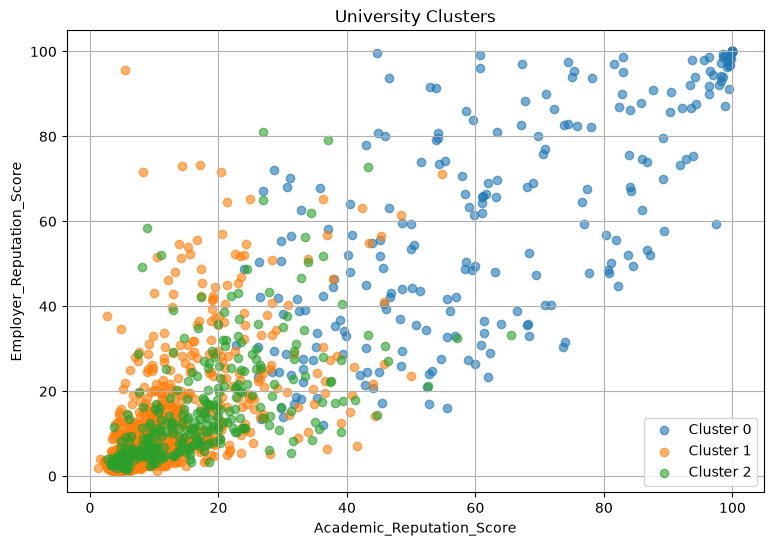

In [ ]:
x_feature = "Academic_Reputation_Score"
y_feature = "Employer_Reputation_Score"

plt.figure(figsize=(9, 6))

for cluster in sorted(data["Cluster"].unique()):
      group = data[data["Cluster"] == cluster]

      plt.scatter(
          group[x_feature],
          group[y_feature],
          label=f"Cluster {cluster}",
          alpha=0.6
      )

plt.xlabel(x_feature)
plt.ylabel(y_feature)
plt.title("University Clusters")
plt.legend()
plt.grid(True)
plt.show()